# Khảo sát dữ liệu (EDA) – TV1

Đọc ba tập đã sinh ở `preprocessing/generate_data.ipynb`, vẽ hình và thống kê cho mục 2 của báo cáo.
Hình lưu ở `eda/figures/`, bảng lưu ở `eda/*.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

ROOT = Path.cwd() if (Path.cwd() / "preprocessing").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from preprocessing.gaussian import X1_RANGE, X2_RANGE, gaussian_2d

DATA_DIR, EDA_DIR = ROOT / "data", ROOT / "eda"
FIG_DIR = EDA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train_pool", "val", "test"]
COLORS = {"train_pool": "tab:green", "val": "tab:orange", "test": "tab:blue"}
LABELS = {"x1": "$x_1$", "x2": "$x_2$", "y": "$y$"}
data = {s: pd.read_csv(DATA_DIR / f"{s}.csv") for s in SPLITS}

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.grid": True, "grid.alpha": 0.3})

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Đã lưu", (FIG_DIR / name).relative_to(ROOT).as_posix())

# Lưới đều trên miền để vẽ bề mặt thật
g1, g2 = np.meshgrid(np.linspace(*X1_RANGE, 201), np.linspace(*X2_RANGE, 401))
G = gaussian_2d(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)

## 1. Bảng thống kê mô tả

In [2]:
stats = pd.concat({s: df.describe().T for s, df in data.items()}, names=["tập", "biến"])
stats["skew"] = [data[s][v].skew() for s, v in stats.index]
stats = stats.rename(columns={"count": "n"}).astype({"n": int})
stats.to_csv(EDA_DIR / "stats.csv", float_format="%.6g")
stats.style.format(precision=4)

## 2. Scatter 3D của ba tập

Đã lưu eda/figures/scatter3d_splits.png


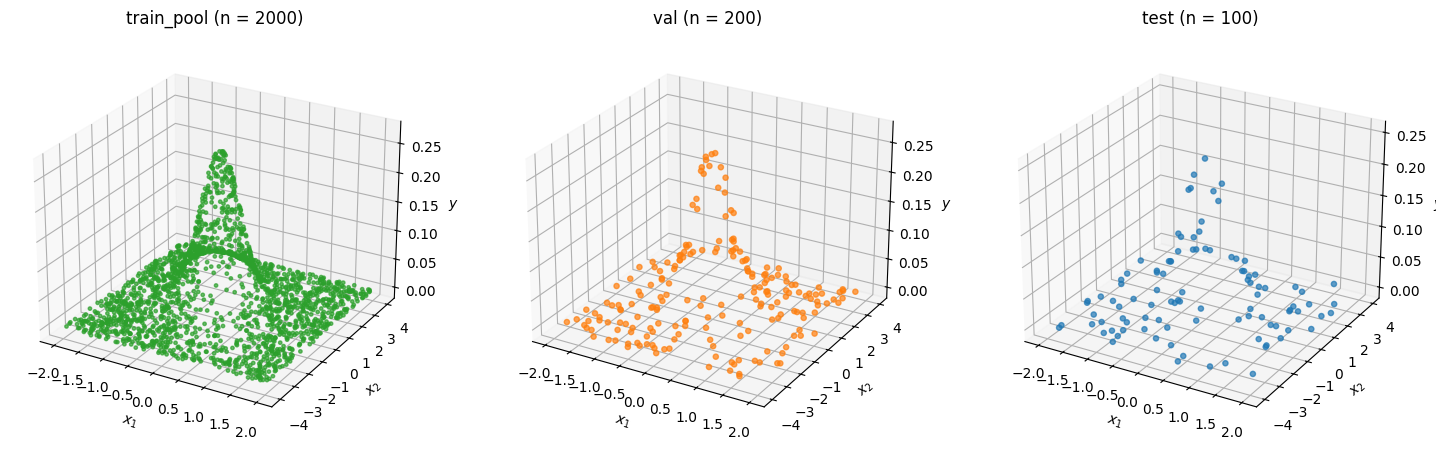

In [3]:
fig = plt.figure(figsize=(18, 5.5))
for i, s in enumerate(SPLITS, 1):
    df = data[s]
    ax = fig.add_subplot(1, 3, i, projection="3d")
    ax.scatter(df.x1, df.x2, df.y, c=COLORS[s], s=6 if s == "train_pool" else 14, alpha=0.7)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$y$", title=f"{s} (n = {len(df)})")
    ax.view_init(elev=25, azim=-60)
save(fig, "scatter3d_splits.png")
plt.show()

## 3. Bề mặt hàm thật và đường đồng mức

Đã lưu eda/figures/true_surface_contour.png


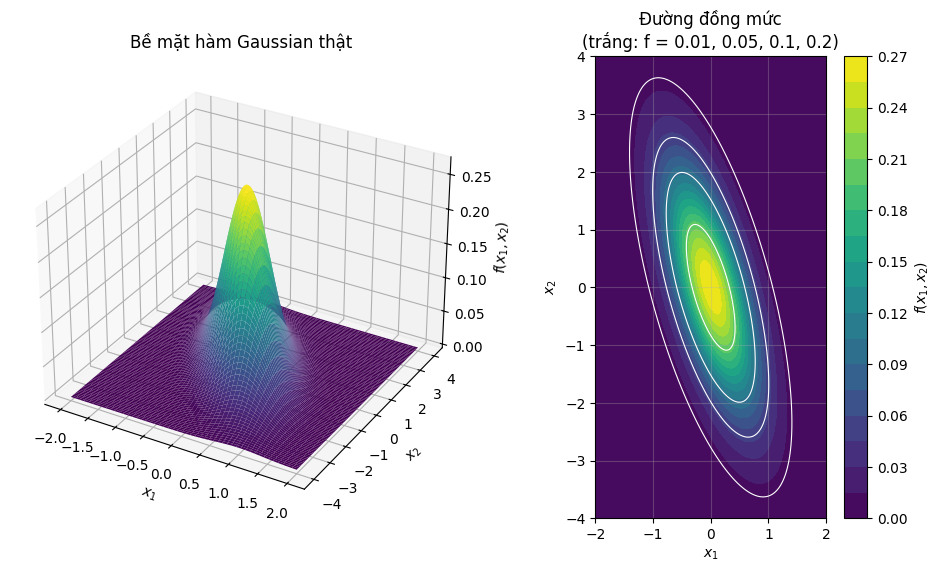

In [4]:
fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.05)
ax = fig.add_subplot(gs[0], projection="3d")
ax.plot_surface(g1, g2, G, cmap="viridis", linewidth=0, antialiased=True, rstride=4, cstride=4)
ax.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$f(x_1, x_2)$", title="Bề mặt hàm Gaussian thật")
ax.view_init(elev=30, azim=-60)

ax = fig.add_subplot(gs[1])
cs = ax.contourf(g1, g2, G, levels=20, cmap="viridis")
ax.contour(g1, g2, G, levels=[0.01, 0.05, 0.1, 0.2], colors="white", linewidths=0.8)
fig.colorbar(cs, ax=ax, label="$f(x_1, x_2)$")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Đường đồng mức\n(trắng: f = 0.01, 0.05, 0.1, 0.2)", aspect="equal")
save(fig, "true_surface_contour.png")
plt.show()

Đã lưu eda/figures/samples_on_contour.png


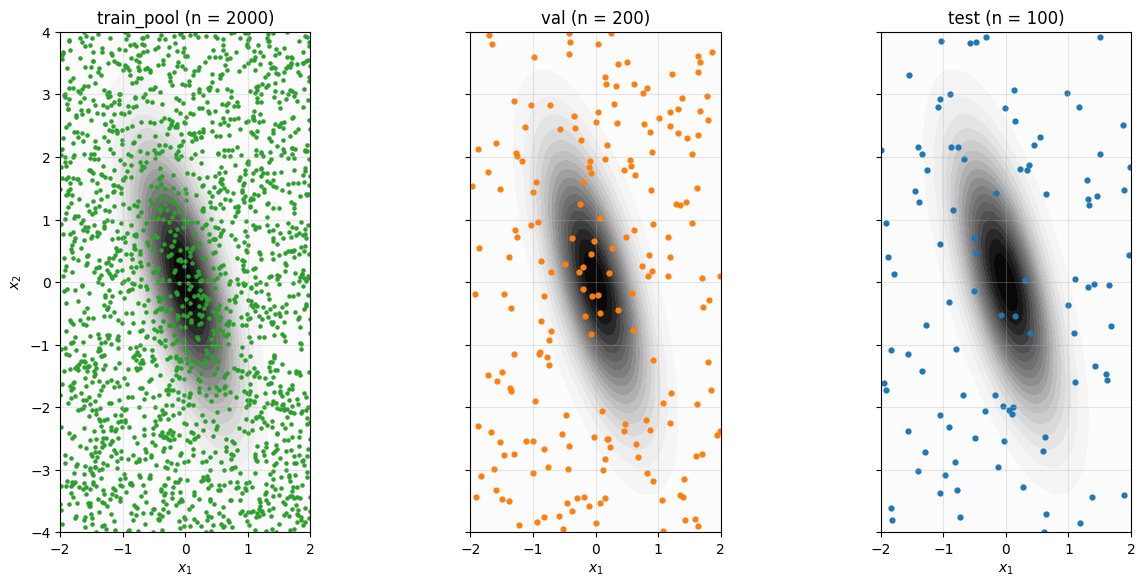

In [5]:
# Vị trí các mẫu trên nền đường đồng mức
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
for ax, s in zip(axes, SPLITS):
    ax.contourf(g1, g2, G, levels=20, cmap="Greys")
    ax.scatter(data[s].x1, data[s].x2, s=5 if s == "train_pool" else 12, c=COLORS[s])
    ax.set(xlabel="$x_1$", title=f"{s} (n = {len(data[s])})", aspect="equal", xlim=X1_RANGE, ylim=X2_RANGE)
axes[0].set_ylabel("$x_2$")
save(fig, "samples_on_contour.png")
plt.show()

## 4. Phân bố của $x_1$, $x_2$, $y$

Đã lưu eda/figures/hist_x1_x2_y.png


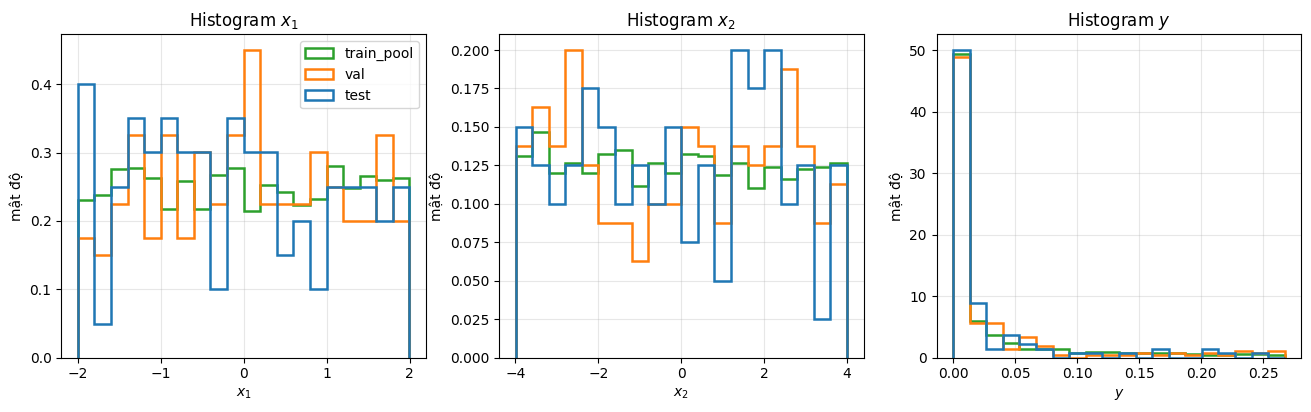

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, v in zip(axes, ["x1", "x2", "y"]):
    bins = np.linspace(min(d[v].min() for d in data.values()), max(d[v].max() for d in data.values()), 21)
    for s in SPLITS:
        ax.hist(data[s][v], bins=bins, density=True, histtype="step", lw=1.8, color=COLORS[s], label=s)
    ax.set(xlabel=LABELS[v], ylabel="mật độ", title=f"Histogram {LABELS[v]}")
axes[0].legend()
save(fig, "hist_x1_x2_y.png")
plt.show()

## 5. Mức độ lệch của $y$

Hàm Gaussian chỉ lớn ở vùng hẹp quanh gốc toạ độ, phần lớn miền có $f \approx 0$.
Phần này đo xem bao nhiêu mẫu thực sự nằm ở vùng có giá trị, vì đó là vùng mạng phải học.

In [7]:
thresholds = [1e-3, 0.01, 0.05, 0.1, 0.2]
area = (X1_RANGE[1] - X1_RANGE[0]) * (X2_RANGE[1] - X2_RANGE[0])
rows = {f"y > {t:g}": {**{s: (data[s].y > t).mean() for s in SPLITS},
                        "tỷ lệ diện tích (lưới)": (G > t).mean()} for t in thresholds}
y_share = pd.DataFrame(rows).T
y_share.to_csv(EDA_DIR / "y_threshold_share.csv", float_format="%.4f")
y_share.style.format("{:.1%}")

,train_pool,val,test,tỷ lệ diện tích (lưới)
y > 0.001,60.8%,59.0%,63.0%,60.0%
y > 0.01,36.9%,37.0%,35.0%,38.0%
y > 0.05,18.9%,18.5%,16.0%,19.4%
y > 0.1,11.7%,10.0%,8.0%,11.4%
y > 0.2,3.8%,5.5%,4.0%,3.4%


Đã lưu eda/figures/y_log_hist_ecdf.png


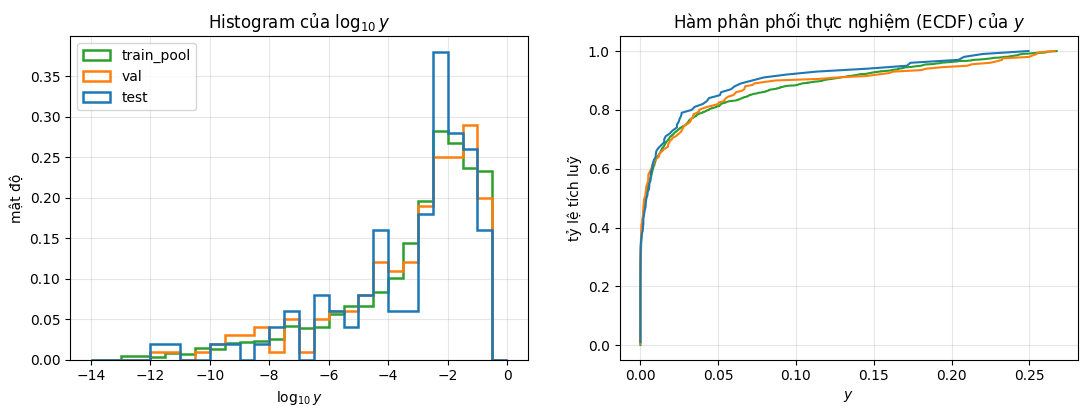

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(-14, 0, 29)
for s in SPLITS:
    axes[0].hist(np.log10(data[s].y), bins=bins, density=True, histtype="step", lw=1.8, color=COLORS[s], label=s)
    y_sorted = np.sort(data[s].y)
    axes[1].plot(y_sorted, np.arange(1, len(y_sorted) + 1) / len(y_sorted), color=COLORS[s], label=s)
axes[0].set(xlabel="$\\log_{10} y$", ylabel="mật độ", title="Histogram của $\\log_{10} y$")
axes[1].set(xlabel="$y$", ylabel="tỷ lệ tích luỹ", title="Hàm phân phối thực nghiệm (ECDF) của $y$")
axes[0].legend()
save(fig, "y_log_hist_ecdf.png")
plt.show()

## 6. Ba tập có cùng phân bố không?

Kiểm định Kolmogorov–Smirnov hai mẫu, so `val` và `test` với `train_pool`.
p-value lớn nghĩa là không có bằng chứng ba tập khác phân bố.

In [9]:
ks = pd.DataFrame([
    {"so sánh": f"train_pool vs {s}", "biến": v, "KS": r.statistic, "p-value": r.pvalue}
    for s in ["val", "test"] for v in ["x1", "x2", "y"]
    for r in [ks_2samp(data["train_pool"][v], data[s][v])]
])
ks.to_csv(EDA_DIR / "ks_tests.csv", index=False, float_format="%.4f")
ks.style.format({"KS": "{:.4f}", "p-value": "{:.3f}"}).hide(axis="index")

so sánh,biến,KS,p-value
train_pool vs val,x1,0.0570,0.580
train_pool vs val,x2,0.0645,0.422
train_pool vs val,y,0.0450,0.842
train_pool vs test,x1,0.0835,0.497
train_pool vs test,x2,0.0580,0.889
train_pool vs test,y,0.0525,0.944


## 7. Các tập con lồng nhau cho Exp A

Exp A dùng `train_pool[:A]` với A = 200, 400, …, 2000. Bảng dưới đây kiểm tra các tập con nhỏ vẫn phủ đều miền
và có đủ mẫu ở vùng đỉnh, để khác biệt giữa các A đến từ số mẫu chứ không phải do lấy mẫu lệch.

In [10]:
pool = data["train_pool"]
subsets = pd.DataFrame([
    {"A": a, "mean_x1": pool.x1[:a].mean(), "mean_x2": pool.x2[:a].mean(), "mean_y": pool.y[:a].mean(),
     "max_y": pool.y[:a].max(), "n(y > 0.05)": int((pool.y[:a] > 0.05).sum()), "tỷ lệ y > 0.05": (pool.y[:a] > 0.05).mean()}
    for a in range(200, 2001, 200)
]).set_index("A")
subsets.to_csv(EDA_DIR / "nested_subsets.csv", float_format="%.4f")
subsets.style.format(precision=4).format({"tỷ lệ y > 0.05": "{:.1%}"})

,mean_x1,mean_x2,mean_y,max_y,n(y > 0.05),tỷ lệ y > 0.05
A,,,,,,
200,-0.024522,-0.205333,0.032201,0.261275,40,20.0%
400,-0.013815,-0.214186,0.031030,0.267541,75,18.8%
600,-0.016054,-0.107134,0.031338,0.267541,115,19.2%
800,-0.022398,-0.008855,0.032426,0.267541,158,19.8%
1000,-0.011289,-0.057012,0.031692,0.267541,191,19.1%
1200,0.000397,-0.056521,0.030668,0.267541,224,18.7%
1400,-0.006838,-0.080190,0.030814,0.267541,262,18.7%
1600,-0.000488,-0.026967,0.031210,0.267541,302,18.9%
1800,0.009712,-0.028605,0.030461,0.267541,333,18.5%


Đã lưu eda/figures/nested_subsets.png


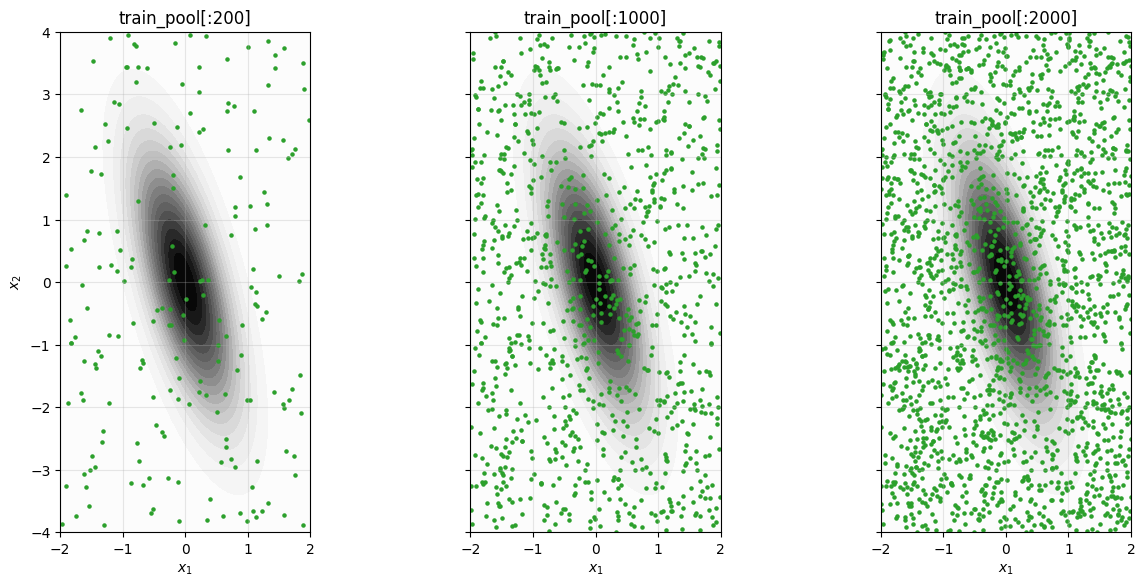

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
for ax, a in zip(axes, [200, 1000, 2000]):
    ax.contourf(g1, g2, G, levels=20, cmap="Greys")
    ax.scatter(pool.x1[:a], pool.x2[:a], s=5, c="tab:green")
    ax.set(xlabel="$x_1$", title=f"train_pool[:{a}]", aspect="equal", xlim=X1_RANGE, ylim=X2_RANGE)
axes[0].set_ylabel("$x_2$")
save(fig, "nested_subsets.png")
plt.show()

## 8. Mốc so sánh: dự đoán hằng số

Mô hình đơn giản nhất luôn dự đoán $\hat y = \bar y_{train}$. Mọi MLP được báo cáo phải có MSE thấp hơn hẳn mốc này
thì mới được coi là đã học được hình dạng hàm.

In [12]:
y_bar = pool.y.mean()
const = pd.DataFrame([
    {"tập": s, "MSE": np.mean((data[s].y - y_bar) ** 2), "MAE": np.mean(np.abs(data[s].y - y_bar)),
     "RMSE": np.sqrt(np.mean((data[s].y - y_bar) ** 2))}
    for s in SPLITS
]).set_index("tập")
const.to_csv(EDA_DIR / "constant_baseline.csv", float_format="%.6g")
print(f"ȳ_train = {y_bar:.6f}")
const.style.format("{:.3e}")

ȳ_train = 0.030951


,MSE,MAE,RMSE
tập,,,
train_pool,3.381e-03,3.998e-02,5.815e-02
val,3.800e-03,4.014e-02,6.164e-02
test,2.737e-03,3.596e-02,5.232e-02


## 9. Nhận xét

1. **Hàm và miền.** $f(0,0) = 0.2690$, trùng với $1/(2\pi\sqrt{0.35})$. Tích phân trên miền $[-2,2]\times[-4,4]$ bằng 0.995,
   nghĩa là miền đề bài chứa gần như toàn bộ khối Gaussian; ở biên $f$ gần như bằng 0.
2. **Hình dạng.** Hệ số tương quan $\rho = -0.5/\sqrt{0.3\cdot 2} \approx -0.65$ nên đỉnh là một elip nghiêng, hẹp theo $x_1$
   ($\sigma_1 \approx 0.55$) và rộng theo $x_2$ ($\sigma_2 \approx 1.41$). Chuẩn hoá $x_1/2$, $x_2/4$ đưa hai độ rộng về khoảng 0.27 và 0.35,
   cân bằng hơn cho mạng.
3. **$y$ rất lệch phải.** Trung bình 0.031 nhưng trung vị chỉ 0.0036, độ lệch (skew) khoảng 2.3. Khoảng 63% mẫu có $y < 0.01$,
   chỉ khoảng 19% mẫu có $y > 0.05$ và 4% mẫu có $y > 0.2$. MSE vì vậy bị chi phối bởi một số ít điểm gần đỉnh;
   khi đọc kết quả cần xem thêm heatmap lỗi theo vị trí, không chỉ một con số MSE.
4. **Ba tập cùng phân bố.** Kiểm định KS cho cả $x_1$, $x_2$, $y$ đều có p-value > 0.4, không có điểm trùng giữa các tập.
   Riêng test chỉ có 100 mẫu và ít điểm ở đỉnh hơn (8% có $y > 0.1$ so với 11.7% ở train_pool, $y_{max}$ = 0.249),
   nên MSE trên test sẽ dao động; đây là lý do chọn mô hình theo val (200 mẫu) và báo cáo nhiều seed.
5. **Tập con cho Exp A.** Tỷ lệ mẫu có $y > 0.05$ ổn định 18.5–20% với mọi A, nên các tập con lồng nhau không bị lệch.
   Tuy nhiên A = 200 chỉ có 40 điểm ở vùng đỉnh, dự kiến là nguồn sai số chính khi A nhỏ.
6. **Mốc hằng số.** Dự đoán $\hat y = \bar y$ cho MSE khoảng $3.4\times10^{-3}$ trên train_pool (bằng phương sai của $y$).
   Đây là cận trên mà mọi cấu hình trong A, B, C phải vượt qua.